# DX799 O1 - Week 2 Jupyter Notebook: Regularized Linear Regression

## Digital Customer Journey and E-Commerce Retention Analytics

**Student:** Javed Aamer

### Goal of this notebook

This notebook extends the Week 1 regression work by asking a different question: **can I control model complexity without giving up useful predictive signal?**

I compare four versions of linear regression:

- ordinary least squares as the unregularized baseline
- Lasso
- Ridge
- Elastic Net

The four cleaned datasets are treated as different views of the same e-commerce customer journey. I do not force them into one table because they have different grains and do not all share a verified row-level key.

The Week 2 lesson emphasizes three practical ideas that I want to make visible in the analysis:

1. Lasso can shrink some coefficients all the way to zero.
2. Ridge usually keeps correlated predictors but shrinks their influence.
3. Elastic Net can sit between those two behaviors.

The point is not to assume regularization is automatically better. I want to see **where it improves generalization, where it mainly simplifies the model, and where no regularization is actually the better choice**.

## 1. Questions I want Week 2 to answer

I used the same four continuous outcomes from the current integrated project so the regularization methods can be compared across very different parts of the customer journey.

1. **Behavior:** Can Lasso simplify the profit model without hurting prediction?
2. **Churn table:** Does regularization improve the cashback model, or is the ordinary linear model already stable?
3. **Products:** Does a smaller product dataset benefit from shrinkage?
4. **Reviews:** Can regularization improve the structured sentiment model even though Week 1 showed that a lot of sentiment variation remains unexplained?
5. How does increasing the penalty strength change validation error?
6. How differently do Lasso and Ridge change the coefficient structure?
7. When would I deliberately choose **no regularization**?

These remain predictive associations, not causal effects.

### Course terminology and scikit-learn terminology

The Week 2 lesson describes the penalty strength using **lambda**. In scikit-learn, the models use the name **`alpha`** for that same general idea: larger values mean stronger regularization.

There is one naming difference worth keeping straight for Elastic Net. The course lesson describes the mixing idea as moving between Lasso and Ridge. In scikit-learn, that mixture is controlled with **`l1_ratio`**:

- near 1 means more Lasso-like
- near 0 means more Ridge-like

I use the scikit-learn parameter names in the code, but the interpretation follows the Week 2 lecture.

Another implementation detail is scaling. Because the penalty acts on coefficient size, I standardize numeric features before fitting the regularized models. Otherwise, variables measured in large units can be penalized differently simply because of their scale.

In [1]:
# Imports and reproducibility

from pathlib import Path
import re
import warnings
import json

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

RANDOM_STATE = 42
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

## 2. Load the four cleaned datasets

I keep the same data architecture used in Week 1:

- **Behavior** is transaction/activity level.
- **Churn** is customer level.
- **Products** is product level.
- **Reviews** is review level.

For behavior, I keep all records from the same customer together when splitting the data. For reviews, I keep reviews from the same product together. That reduces leakage from repeated entities.

The product and review parsing below only converts already-cleaned text fields such as formatted ratings and counts into numeric variables that the regression models can use.

In [2]:
# Locate the cleaned data folder.

candidate_dirs = [
    Path("data"),
    Path("data_pkg"),
    Path("../data"),
    Path("../data_pkg"),
    Path("/mnt/data/dx799_rebuild/data/cleaned_week2_output"),
]

DATA_DIR = next(
    (p for p in candidate_dirs if (p / "behavior_clean.csv").exists()),
    None,
)

if DATA_DIR is None:
    raise FileNotFoundError(
        "Could not find behavior_clean.csv, churn_clean.csv, products_clean.csv, and reviews_clean.csv."
    )

behavior = pd.read_csv(DATA_DIR / "behavior_clean.csv", low_memory=False)
churn = pd.read_csv(DATA_DIR / "churn_clean.csv", low_memory=False)
products = pd.read_csv(DATA_DIR / "products_clean.csv", low_memory=False)
reviews = pd.read_csv(DATA_DIR / "reviews_clean.csv", low_memory=False)

print(f"Loaded data from: {DATA_DIR}")

Loaded data from: data


In [3]:
# Parse the product and review fields needed in this week's models.

products["rating_stars_num"] = pd.to_numeric(
    products["rating_stars"].astype(str).str.extract(r"([0-9.]+)")[0],
    errors="coerce",
)

products["rating_count_num"] = pd.to_numeric(
    products["rating_count"]
        .astype(str)
        .str.replace(",", "", regex=False)
        .str.extract(r"([0-9]+)")[0],
    errors="coerce",
)

def parse_recent_purchases(value):
    match = re.search(r"([\d,.]+)\s*([Kk]?)", str(value))
    if not match:
        return np.nan

    number = float(match.group(1).replace(",", ""))
    return number * 1000 if match.group(2) else number

products["recent_purchases_num"] = products["recent_purchases"].map(parse_recent_purchases)

products["list_price_num"] = pd.to_numeric(
    products["list_price"]
        .astype(str)
        .str.replace(",", "", regex=False)
        .str.extract(r"\$([0-9.]+)")[0],
    errors="coerce",
)

products["discount_pct"] = np.where(
    products["list_price_num"] > 0,
    (products["list_price_num"] - products["price_value"])
    / products["list_price_num"],
    0,
)

products["main_rank"] = pd.to_numeric(
    products["best_sellers_rank"]
        .astype(str)
        .str.replace(",", "", regex=False)
        .str.extract(r"#([0-9]+)")[0],
    errors="coerce",
)

products["in_stock"] = (
    products["availability"]
    .astype(str)
    .str.lower()
    .str.contains("in stock")
    .astype(int)
)

products["description_len"] = products["product_description"].astype(str).str.len()
products["review_summary_len"] = products["customer_review_summary"].astype(str).str.len()
products["log_rating_count"] = np.log1p(products["rating_count_num"])

reviews["review_len"] = (
    reviews["cleaned_review_text"].astype(str).str.split().str.len()
)
reviews["verified_int"] = reviews["verifiedPurchase"].astype(int)

In [4]:
# Project-wide dataset roles.

role_table = pd.DataFrame(
    {
        "Dataset": ["Behavior", "Churn", "Products", "Reviews"],
        "Rows": [len(behavior), len(churn), len(products), len(reviews)],
        "Grain": [
            "order / activity record",
            "customer",
            "product",
            "review",
        ],
        "Week 2 outcome": [
            "Profit",
            "CashbackAmount",
            "log(1 + rating count)",
            "sentiment_score",
        ],
        "Regularization question": [
            "Can Lasso remove weak transaction/context terms?",
            "Does a strong customer-value model need a penalty?",
            "Can shrinkage stabilize a smaller product model?",
            "Can shrinkage slightly improve structured sentiment prediction?",
        ],
    }
)

display(role_table)

,Dataset,Rows,Grain,Week 2 outcome,Regularization question
0,Behavior,51289,order / activity record,Profit,Can Lasso remove weak transaction/context terms?
1,Churn,5630,customer,CashbackAmount,Does a strong customer-value model need a pena...
2,Products,728,product,log(1 + rating count),Can shrinkage stabilize a smaller product model?
3,Reviews,6327,review,sentiment_score,Can shrinkage slightly improve structured sent...


## 3. Modeling setup

I use the same core predictor sets across the four Week 2 regression tasks. This keeps the comparison focused on the **effect of the penalty**, not on changing the data and the model at the same time.

I intentionally do **not** create every possible polynomial term here. Week 1 already tested nonlinear expansion. Week 2 is about what happens when the same design matrix is subjected to L1, L2, or mixed regularization.

The test set is held out until the end. Hyperparameters are chosen using a separate validation portion of the training data. For behavior and reviews, the split is group-aware so the same customer or product does not appear on both sides of a split.

In [5]:
REG_TASKS = {
    "Behavior": {
        "df": behavior,
        "target": "Profit",
        "group": "Customer ID",
        "numeric": ["Sales", "Quantity", "Discount", "Browsing Time (min)", "Age"],
        "categorical": ["Segment", "Ship Mode", "Product Category", "Order Priority"],
    },
    "Churn": {
        "df": churn,
        "target": "CashbackAmount",
        "group": None,
        "numeric": [
            "Tenure",
            "WarehouseToHome",
            "HourSpendOnApp",
            "NumberOfDeviceRegistered",
            "SatisfactionScore",
            "NumberOfAddress",
            "Complain",
            "OrderAmountHikeFromlastYear",
            "CouponUsed",
            "OrderCount",
            "DaySinceLastOrder",
        ],
        "categorical": [
            "PreferredLoginDevice",
            "PreferredPaymentMode",
            "PreferedOrderCat",
            "MaritalStatus",
        ],
    },
    "Products": {
        "df": products,
        "target": "log_rating_count",
        "group": None,
        "numeric": [
            "price_value",
            "rating_stars_num",
            "recent_purchases_num",
            "discount_pct",
            "main_rank",
            "rank_1",
            "description_len",
            "review_summary_len",
        ],
        "categorical": ["in_stock"],
    },
    "Reviews": {
        "df": reviews,
        "target": "sentiment_score",
        "group": "productASIN",
        "numeric": [
            "rating",
            "helpfulVoteCount",
            "reviewPosition",
            "review_len",
            "verified_int",
        ],
        "categorical": [],
    },
}

### Why these outcomes?

The four targets answer different parts of the capstone question.

- `Profit` measures transaction economics.
- `CashbackAmount` is a continuous customer-value outcome that fits linear regression more naturally than the binary churn label.
- `log_rating_count` is a stabilized measure of accumulated product attention.
- `sentiment_score` is a continuous post-purchase experience measure.

I report **RMSE, MAE, and R2**. RMSE is my main tuning metric because larger misses matter more, MAE keeps the average absolute miss interpretable, and R2 shows how much outcome variation the model explains.

In [6]:
def split_three(df, target, group_col=None, random_state=RANDOM_STATE):
    index = np.arange(len(df))

    if group_col is not None:
        groups = df[group_col].astype(str).values

        first_split = GroupShuffleSplit(
            n_splits=1,
            test_size=0.20,
            random_state=random_state,
        )
        train_validation, test = next(
            first_split.split(index, groups=groups)
        )

        second_split = GroupShuffleSplit(
            n_splits=1,
            test_size=0.20,
            random_state=random_state + 1,
        )
        train_relative, validation_relative = next(
            second_split.split(
                train_validation,
                groups=groups[train_validation],
            )
        )

        train = train_validation[train_relative]
        validation = train_validation[validation_relative]

    else:
        train_validation, test = train_test_split(
            index,
            test_size=0.20,
            random_state=random_state,
        )

        train, validation = train_test_split(
            train_validation,
            test_size=0.20,
            random_state=random_state + 1,
        )

    return train, validation, test


def make_preprocessor(task):
    transformers = []

    numeric_pipe = Pipeline(
        [
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]
    )
    transformers.append(("num", numeric_pipe, task["numeric"]))

    if task["categorical"]:
        categorical_pipe = Pipeline(
            [
                ("imputer", SimpleImputer(strategy="most_frequent")),
                (
                    "onehot",
                    OneHotEncoder(handle_unknown="ignore", drop="first"),
                ),
            ]
        )
        transformers.append(("cat", categorical_pipe, task["categorical"]))

    return ColumnTransformer(transformers)


def regression_metrics(y_true, prediction):
    return {
        "RMSE": mean_squared_error(y_true, prediction) ** 0.5,
        "MAE": mean_absolute_error(y_true, prediction),
        "R2": r2_score(y_true, prediction),
    }

## 4. Establish the unregularized baseline

Before adding penalties, I fit ordinary least squares on the same standardized and encoded features.

This matters because a regularized model should be judged against a fair baseline. If Ridge, Lasso, or Elastic Net cannot improve prediction or simplify the model, then adding a penalty is not automatically a better modeling decision.

In [7]:
# Prepare each dataset once and keep the train/validation/test partitions for the rest of the notebook.

prepared = {}
baseline_rows = []

for name, task in REG_TASKS.items():
    df = task["df"]
    train_idx, validation_idx, test_idx = split_three(
        df,
        task["target"],
        task["group"],
    )

    preprocessor = make_preprocessor(task)

    X_train = preprocessor.fit_transform(df.iloc[train_idx])
    X_validation = preprocessor.transform(df.iloc[validation_idx])
    X_test = preprocessor.transform(df.iloc[test_idx])

    y_train = df.iloc[train_idx][task["target"]].values
    y_validation = df.iloc[validation_idx][task["target"]].values
    y_test = df.iloc[test_idx][task["target"]].values

    feature_names = preprocessor.get_feature_names_out()

    baseline = LinearRegression().fit(X_train, y_train)
    test_prediction = baseline.predict(X_test)

    prepared[name] = {
        "task": task,
        "preprocessor": preprocessor,
        "X_train": X_train,
        "X_validation": X_validation,
        "X_test": X_test,
        "y_train": y_train,
        "y_validation": y_validation,
        "y_test": y_test,
        "feature_names": feature_names,
        "baseline": baseline,
    }

    baseline_rows.append(
        {
            "Dataset": name,
            "Transformed coefficients": len(feature_names),
            **regression_metrics(y_test, test_prediction),
        }
    )

baseline_table = pd.DataFrame(baseline_rows)
display(baseline_table.round(4))

,Dataset,Transformed coefficients,RMSE,MAE,R2
0,Behavior,16,15.9902,12.7502,0.8940
1,Churn,26,17.6372,10.9955,0.8732
2,Products,9,2.1165,1.6430,0.2254
3,Reviews,5,0.2031,0.1504,0.1284


### Baseline observation

The four problems are not equally predictable, and that is useful context before regularization.

- Behavior profit already has a strong linear signal.
- Cashback amount is also explained well by the customer features.
- Product rating volume is much harder to explain.
- Structured review metadata explains only a modest portion of sentiment variation.

That means I should not expect the same regularization strategy to win everywhere.

## 5. How much regularization is useful?

The Week 2 lesson recommends trying penalty strengths across a wide range, preferably on a logarithmic scale. I follow that idea with values from very weak to very strong regularization.

For **Lasso** and **Ridge**, I record validation RMSE for each alpha. Lower RMSE is better.

This lets me see the bias-variance tradeoff directly:

- very small alpha behaves almost like ordinary least squares
- moderate alpha can reduce variance and stabilize coefficients
- very large alpha can overshrink useful signal and increase error

The test set is still untouched at this point.

In [8]:
alpha_grid = np.logspace(-4, 2, 10)
elastic_l1_ratios = [0.10, 0.25, 0.50, 0.75, 0.90]

curve_rows = []
elastic_curve_rows = []
model_rows = []
fitted_models = {}

for name, info in prepared.items():
    X_train = info["X_train"]
    X_validation = info["X_validation"]
    X_test = info["X_test"]
    y_train = info["y_train"]
    y_validation = info["y_validation"]
    y_test = info["y_test"]

    # OLS baseline
    ols = info["baseline"]
    ols_test = ols.predict(X_test)
    model_rows.append(
        {
            "Dataset": name,
            "Model": "OLS",
            "alpha": np.nan,
            "l1_ratio": np.nan,
            "Nonzero coefficients": int(np.sum(np.abs(ols.coef_) > 1e-8)),
            **regression_metrics(y_test, ols_test),
        }
    )
    fitted_models[(name, "OLS")] = ols

    # Ridge and Lasso alpha search
    for model_name in ["Ridge", "Lasso"]:
        candidates = []

        for alpha in alpha_grid:
            if model_name == "Ridge":
                model = Ridge(alpha=alpha)
            else:
                model = Lasso(alpha=alpha, max_iter=50000)

            model.fit(X_train, y_train)

            validation_prediction = model.predict(X_validation)
            validation_rmse = (
                mean_squared_error(
                    y_validation,
                    validation_prediction,
                )
                ** 0.5
            )

            curve_rows.append(
                {
                    "Dataset": name,
                    "Model": model_name,
                    "alpha": alpha,
                    "Validation RMSE": validation_rmse,
                    "Nonzero coefficients": int(
                        np.sum(np.abs(model.coef_) > 1e-8)
                    ),
                    "Coefficient norm": np.linalg.norm(model.coef_),
                }
            )

            candidates.append(
                (
                    validation_rmse,
                    alpha,
                    model,
                )
            )

        _, best_alpha, best_model = min(
            candidates,
            key=lambda row: row[0],
        )

        test_prediction = best_model.predict(X_test)

        model_rows.append(
            {
                "Dataset": name,
                "Model": model_name,
                "alpha": best_alpha,
                "l1_ratio": np.nan,
                "Nonzero coefficients": int(
                    np.sum(np.abs(best_model.coef_) > 1e-8)
                ),
                **regression_metrics(y_test, test_prediction),
            }
        )

        fitted_models[(name, model_name)] = best_model

    # Elastic Net search over both penalty strength and L1/L2 mix
    elastic_candidates = []

    for l1_ratio in elastic_l1_ratios:
        for alpha in alpha_grid:
            model = ElasticNet(
                alpha=alpha,
                l1_ratio=l1_ratio,
                max_iter=50000,
            )
            model.fit(X_train, y_train)

            validation_prediction = model.predict(X_validation)
            validation_rmse = (
                mean_squared_error(
                    y_validation,
                    validation_prediction,
                )
                ** 0.5
            )

            elastic_curve_rows.append(
                {
                    "Dataset": name,
                    "alpha": alpha,
                    "l1_ratio": l1_ratio,
                    "Validation RMSE": validation_rmse,
                    "Nonzero coefficients": int(
                        np.sum(np.abs(model.coef_) > 1e-8)
                    ),
                }
            )

            elastic_candidates.append(
                (
                    validation_rmse,
                    alpha,
                    l1_ratio,
                    model,
                )
            )

    _, best_alpha, best_l1_ratio, best_model = min(
        elastic_candidates,
        key=lambda row: row[0],
    )

    test_prediction = best_model.predict(X_test)

    model_rows.append(
        {
            "Dataset": name,
            "Model": "Elastic Net",
            "alpha": best_alpha,
            "l1_ratio": best_l1_ratio,
            "Nonzero coefficients": int(
                np.sum(np.abs(best_model.coef_) > 1e-8)
            ),
            **regression_metrics(y_test, test_prediction),
        }
    )

    fitted_models[(name, "Elastic Net")] = best_model

alpha_curves = pd.DataFrame(curve_rows)
elastic_curves = pd.DataFrame(elastic_curve_rows)
week2_results = pd.DataFrame(model_rows)

display(week2_results.round(4))

,Dataset,Model,alpha,l1_ratio,Nonzero coefficients,RMSE,MAE,R2
0,Behavior,OLS,NaN,NaN,16,15.9902,12.7502,0.8940
1,Behavior,Ridge,0.0001,NaN,16,15.9902,12.7502,0.8940
2,Behavior,Lasso,0.0464,NaN,8,15.9899,12.7610,0.8940
3,Behavior,Elastic Net,0.0022,0.9000,16,15.9900,12.7517,0.8940
4,Churn,OLS,NaN,NaN,26,17.6372,10.9955,0.8732
5,Churn,Ridge,0.0001,NaN,26,17.6372,10.9955,0.8732
6,Churn,Lasso,0.0001,NaN,26,17.6372,10.9953,0.8732
7,Churn,Elastic Net,0.0001,0.9000,26,17.6373,10.9954,0.8732
8,Products,OLS,NaN,NaN,9,2.1165,1.6430,0.2254
9,Products,Ridge,0.0001,NaN,9,2.1165,1.6430,0.2254


## 6. Alpha sensitivity curves

The initial Week 2 notebook did this for one dataset. I kept that idea because it is one of the clearest ways to connect the code back to the lecture, but now I show it separately for all four datasets.

I plot Ridge and Lasso on the same figure for each dataset. I am mainly looking for two things:

1. whether the error curve has a clear minimum away from zero
2. how quickly performance deteriorates when the penalty becomes too strong

The absolute RMSE scale differs across outcomes, so each dataset gets its own chart rather than forcing unrelated units onto one axis.

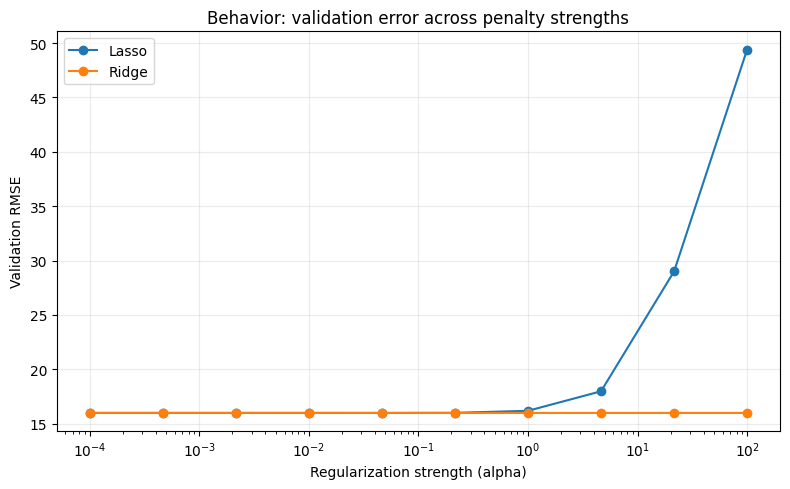

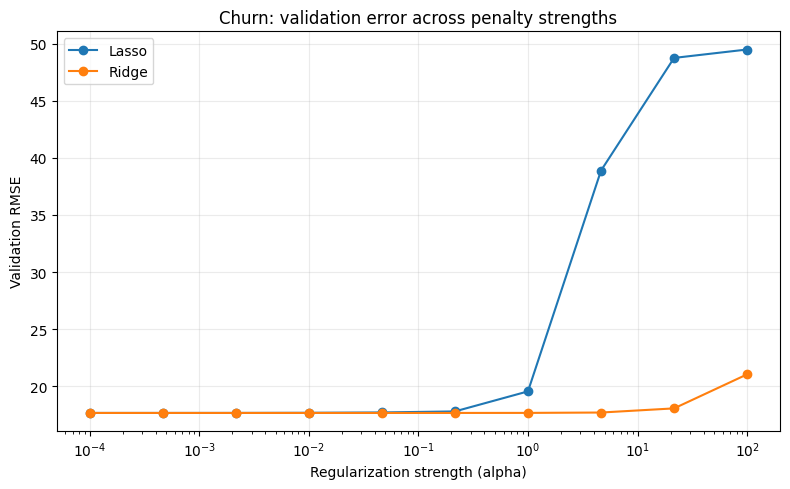

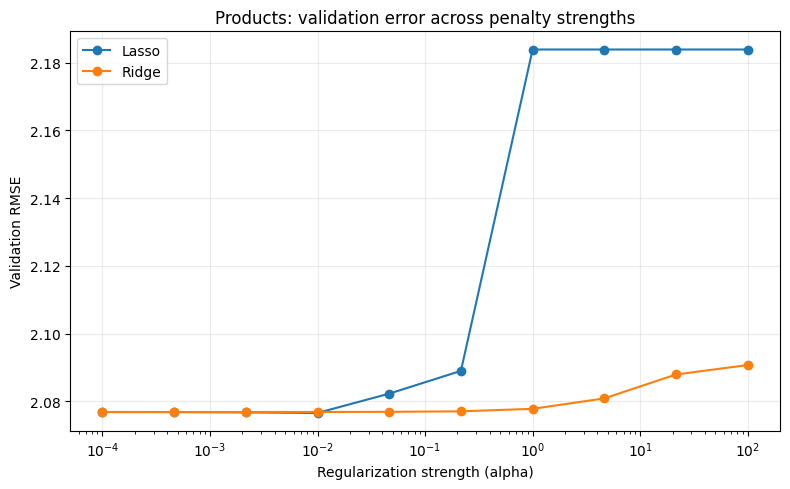

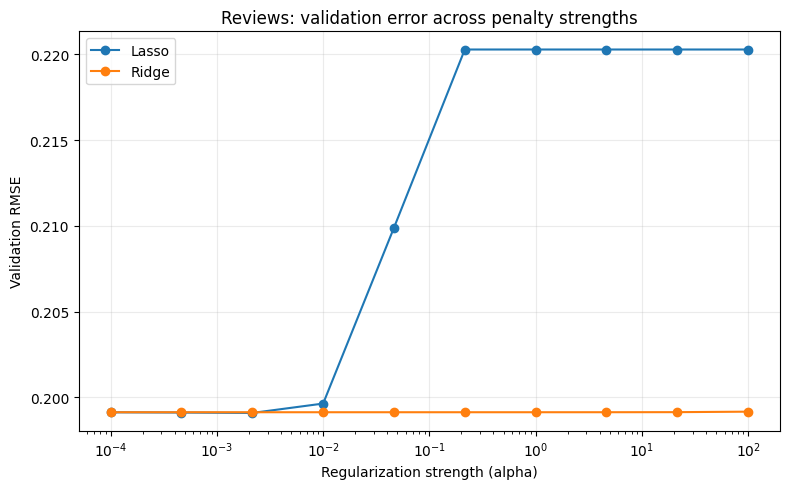

In [9]:
for dataset_name in REG_TASKS:
    subset = alpha_curves[
        alpha_curves["Dataset"] == dataset_name
    ]

    fig, ax = plt.subplots(figsize=(8, 5))

    for model_name in ["Lasso", "Ridge"]:
        model_curve = subset[
            subset["Model"] == model_name
        ]

        ax.plot(
            model_curve["alpha"],
            model_curve["Validation RMSE"],
            marker="o",
            label=model_name,
        )

    ax.set_xscale("log")
    ax.set_xlabel("Regularization strength (alpha)")
    ax.set_ylabel("Validation RMSE")
    ax.set_title(f"{dataset_name}: validation error across penalty strengths")
    ax.grid(alpha=0.25)
    ax.legend()
    plt.tight_layout()
    plt.show()

### What the alpha curves tell me

The curves are more informative than simply reporting the chosen alpha.

- **Behavior:** Lasso has a shallow minimum at a small but nonzero penalty. Stronger penalties eventually hurt, but the moderate L1 penalty is enough to remove weak terms.
- **Churn:** the best values are essentially at the unregularized end of the search. The model does not need meaningful shrinkage for predictive accuracy.
- **Products:** stronger L1 shrinkage worsens validation performance. The small sample does not automatically mean that heavy regularization is useful.
- **Reviews:** a small Lasso penalty helps slightly, but the curve is shallow. I would describe this as a modest gain, not a dramatic model change.

This already answers one of the course's "Think About It" questions: there are situations where I would prefer regression with **no meaningful regularization**.

## 7. Lasso versus Ridge: what happens to the coefficients?

Prediction metrics alone do not show the main conceptual difference between Lasso and Ridge.

The lecture emphasizes that:

- Lasso can remove terms by making their coefficients zero.
- Ridge usually keeps the terms but shrinks them.
- correlated predictors can therefore behave very differently under the two penalties.

I track two simple diagnostics while alpha increases:

- the number of nonzero Lasso coefficients
- the total Ridge coefficient magnitude

This makes the two regularization behaviors visible rather than only describing them.

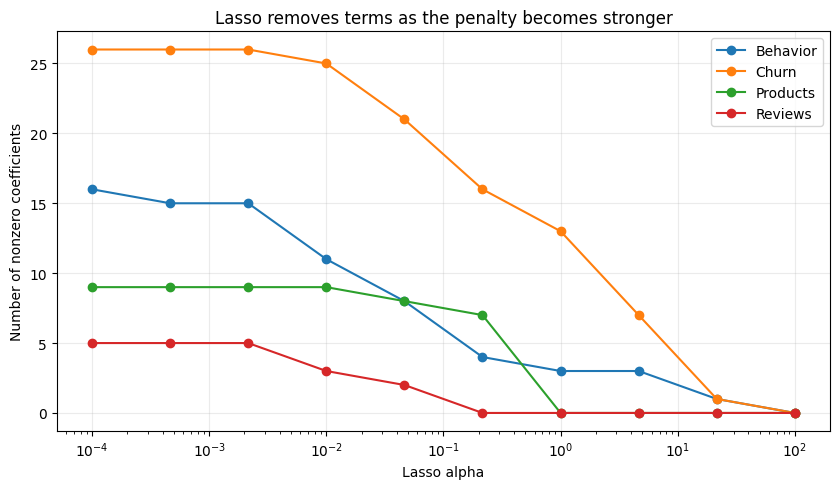

In [10]:
# Lasso sparsity across alpha.

fig, ax = plt.subplots(figsize=(8.5, 5))

for dataset_name in REG_TASKS:
    subset = alpha_curves[
        (alpha_curves["Dataset"] == dataset_name)
        & (alpha_curves["Model"] == "Lasso")
    ]

    ax.plot(
        subset["alpha"],
        subset["Nonzero coefficients"],
        marker="o",
        label=dataset_name,
    )

ax.set_xscale("log")
ax.set_xlabel("Lasso alpha")
ax.set_ylabel("Number of nonzero coefficients")
ax.set_title("Lasso removes terms as the penalty becomes stronger")
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

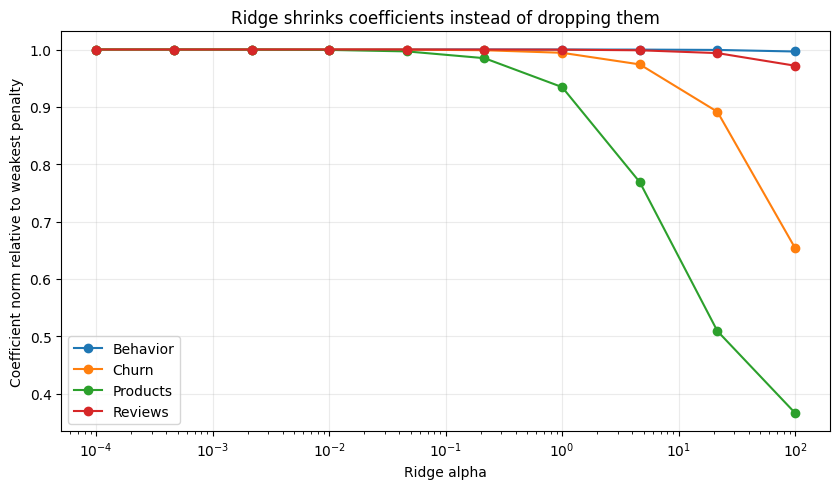

In [11]:
# Ridge shrinkage across alpha.
# I normalize the coefficient norm within each dataset so different target scales can be compared.

fig, ax = plt.subplots(figsize=(8.5, 5))

for dataset_name in REG_TASKS:
    subset = alpha_curves[
        (alpha_curves["Dataset"] == dataset_name)
        & (alpha_curves["Model"] == "Ridge")
    ].copy()

    subset["Relative coefficient norm"] = (
        subset["Coefficient norm"]
        / subset["Coefficient norm"].iloc[0]
    )

    ax.plot(
        subset["alpha"],
        subset["Relative coefficient norm"],
        marker="o",
        label=dataset_name,
    )

ax.set_xscale("log")
ax.set_xlabel("Ridge alpha")
ax.set_ylabel("Coefficient norm relative to weakest penalty")
ax.set_title("Ridge shrinks coefficients instead of dropping them")
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

### Coefficient behavior observation

These plots make the distinction from the lecture very clear.

Lasso eventually turns coefficients off. Ridge does not create the same sparsity pattern; instead, the coefficient vector gets progressively smaller.

That distinction matters for the capstone:

- if I need a compact set of variables for explanation or maintenance, Lasso is attractive
- if several correlated signals are all meaningful and I do not want the model to arbitrarily keep one while dropping another, Ridge is more defensible
- if I want some feature selection without going fully Lasso, Elastic Net is the compromise

## 8. Compare the selected models on untouched test data

Now I use the test set for the first time.

The numerical table still reports RMSE, MAE, R2, alpha, and sparsity. For the visualization, I do **not** use a normal grouped R2 bar chart because OLS, Ridge, Lasso, and Elastic Net are extremely close on several datasets. Bars drawn from zero would look identical even when the small differences are real.

Instead, I plot the **percentage change in test RMSE relative to OLS within each dataset**. This makes the decision question clearer:

- values below zero mean regularization improved RMSE
- values above zero mean it made RMSE worse
- values near zero mean prediction is essentially unchanged

That is a more honest visualization of what Week 2 actually found.

In [12]:
comparison = week2_results.copy()

comparison["RMSE change vs OLS"] = comparison.groupby("Dataset")["RMSE"].transform(
    lambda values: values - values.iloc[0]
)

comparison["R2 change vs OLS"] = comparison.groupby("Dataset")["R2"].transform(
    lambda values: values - values.iloc[0]
)

display(
    comparison[
        [
            "Dataset",
            "Model",
            "alpha",
            "l1_ratio",
            "Nonzero coefficients",
            "RMSE",
            "MAE",
            "R2",
            "RMSE change vs OLS",
            "R2 change vs OLS",
        ]
    ].round(5)
)

,Dataset,Model,alpha,l1_ratio,Nonzero coefficients,RMSE,MAE,R2,RMSE change vs OLS,R2 change vs OLS
0,Behavior,OLS,NaN,NaN,16,15.9902,12.7502,0.8940,0.0000,0.0000
1,Behavior,Ridge,0.0001,NaN,16,15.9902,12.7502,0.8940,0.0000,-0.0000
2,Behavior,Lasso,0.0464,NaN,8,15.9899,12.7610,0.8940,-0.0003,0.0000
3,Behavior,Elastic Net,0.0022,0.9000,16,15.9900,12.7517,0.8940,-0.0002,0.0000
4,Churn,OLS,NaN,NaN,26,17.6372,10.9955,0.8732,0.0000,0.0000
5,Churn,Ridge,0.0001,NaN,26,17.6372,10.9955,0.8732,0.0000,-0.0000
6,Churn,Lasso,0.0001,NaN,26,17.6371,10.9953,0.8732,-0.0000,0.0000
7,Churn,Elastic Net,0.0001,0.9000,26,17.6373,10.9954,0.8732,0.0001,-0.0000
8,Products,OLS,NaN,NaN,9,2.1165,1.6430,0.2254,0.0000,0.0000
9,Products,Ridge,0.0001,NaN,9,2.1165,1.6430,0.2254,0.0000,-0.0000


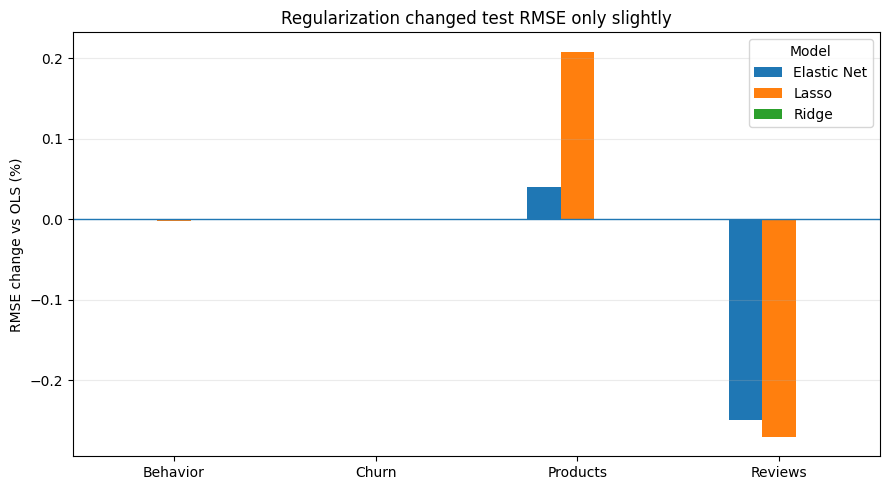

,Dataset,Model,RMSE % change vs OLS
0,Behavior,Ridge,0.0000
1,Behavior,Lasso,-0.0018
2,Behavior,Elastic Net,-0.0010
3,Churn,Ridge,0.0000
4,Churn,Lasso,-0.0002
5,Churn,Elastic Net,0.0006
6,Products,Ridge,0.0000
7,Products,Lasso,0.2082
8,Products,Elastic Net,0.0404
9,Reviews,Ridge,-0.0000


In [13]:
# Compare each regularized model with OLS on the same dataset.
# Using percent change avoids a visually misleading chart where nearly identical
# absolute R2 values produce bars that look exactly the same.

plot_rows = []

for dataset_name in week2_results["Dataset"].unique():
    subset = week2_results[
        week2_results["Dataset"] == dataset_name
    ].copy()

    ols_rmse = subset.loc[
        subset["Model"] == "OLS",
        "RMSE",
    ].iloc[0]

    for _, row in subset.iterrows():
        if row["Model"] == "OLS":
            continue

        plot_rows.append(
            {
                "Dataset": dataset_name,
                "Model": row["Model"],
                "RMSE % change vs OLS": (
                    (row["RMSE"] - ols_rmse) / ols_rmse
                ) * 100,
            }
        )

rmse_change_plot = pd.DataFrame(plot_rows)

pivot_rmse_change = rmse_change_plot.pivot(
    index="Dataset",
    columns="Model",
    values="RMSE % change vs OLS",
)

ax = pivot_rmse_change.plot(kind="bar", figsize=(9, 5))
ax.axhline(0, linewidth=1)
ax.set_title("Regularization changed test RMSE only slightly")
ax.set_xlabel("")
ax.set_ylabel("RMSE change vs OLS (%)")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

display(rmse_change_plot.round(4))

,Dataset,Original coefficients,Lasso coefficients retained,Coefficients removed,Percent removed
0,Behavior,16,8,8,50.0000
1,Churn,26,26,0,0.0000
2,Products,9,9,0,0.0000
3,Reviews,5,5,0,0.0000


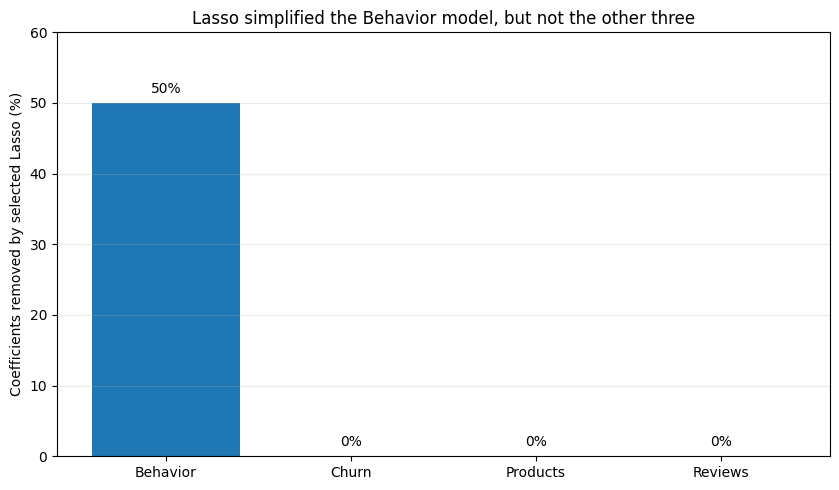

In [14]:
# Lasso is the method in this week's lesson that is expected to create exact zeros.
# Instead of plotting OLS and Ridge bars that are expected to have the same count,
# show exactly how many terms the selected Lasso model removed.

lasso_sparsity_rows = []

for dataset_name in week2_results["Dataset"].unique():
    subset = week2_results[
        week2_results["Dataset"] == dataset_name
    ]

    ols_count = int(
        subset.loc[
            subset["Model"] == "OLS",
            "Nonzero coefficients",
        ].iloc[0]
    )

    lasso_count = int(
        subset.loc[
            subset["Model"] == "Lasso",
            "Nonzero coefficients",
        ].iloc[0]
    )

    lasso_sparsity_rows.append(
        {
            "Dataset": dataset_name,
            "Original coefficients": ols_count,
            "Lasso coefficients retained": lasso_count,
            "Coefficients removed": ols_count - lasso_count,
            "Percent removed": (
                (ols_count - lasso_count) / ols_count
            ) * 100,
        }
    )

lasso_sparsity = pd.DataFrame(lasso_sparsity_rows)
display(lasso_sparsity.round(1))

fig, ax = plt.subplots(figsize=(8.5, 5))
bars = ax.bar(
    lasso_sparsity["Dataset"],
    lasso_sparsity["Percent removed"],
)

for bar, value in zip(bars, lasso_sparsity["Percent removed"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 1,
        f"{value:.0f}%",
        ha="center",
        va="bottom",
    )

ax.set_ylim(0, max(55, lasso_sparsity["Percent removed"].max() + 10))
ax.set_ylabel("Coefficients removed by selected Lasso (%)")
ax.set_title("Lasso simplified the Behavior model, but not the other three")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 9. Elastic Net as the compromise

Elastic Net is useful when Lasso feels too aggressive but Ridge leaves too many terms active.

The selected `l1_ratio` is **0.90 for all four datasets** in this search. That result is valid, but plotting four identical bars at 0.90 would not teach me anything. I therefore plot the **best validation RMSE obtained at each candidate `l1_ratio`** for each dataset.

This lets me see whether the selection of 0.90 is strongly preferred or whether the different mixtures perform almost the same. The latter is important because a hyperparameter can technically win while having very little practical effect.

,Dataset,alpha,l1_ratio,Nonzero coefficients,RMSE,R2
0,Behavior,0.0022,0.9000,16,15.9900,0.8940
1,Churn,0.0001,0.9000,26,17.6373,0.8732
2,Products,0.0022,0.9000,9,2.1173,0.2248
3,Reviews,0.0022,0.9000,5,0.2026,0.1327


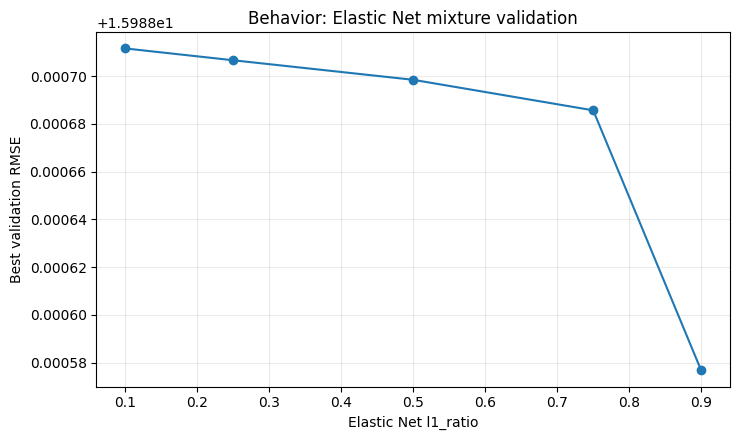

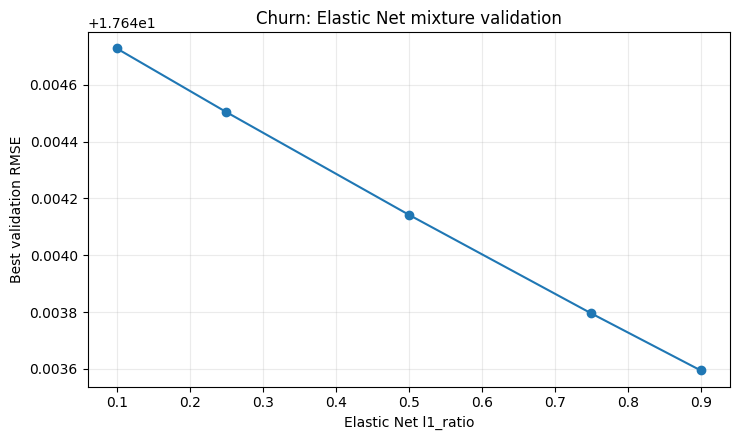

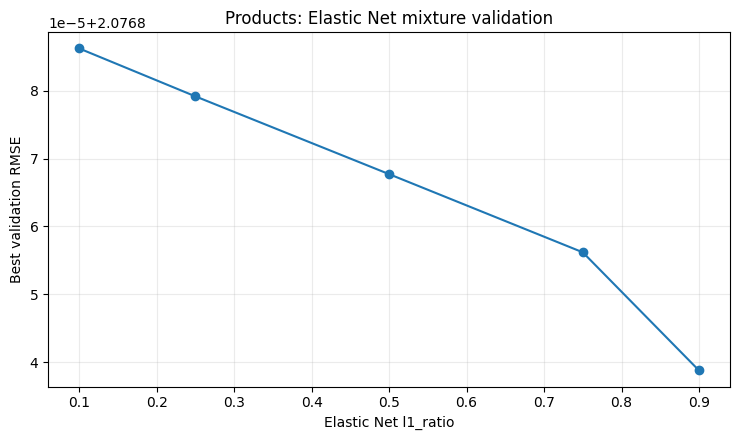

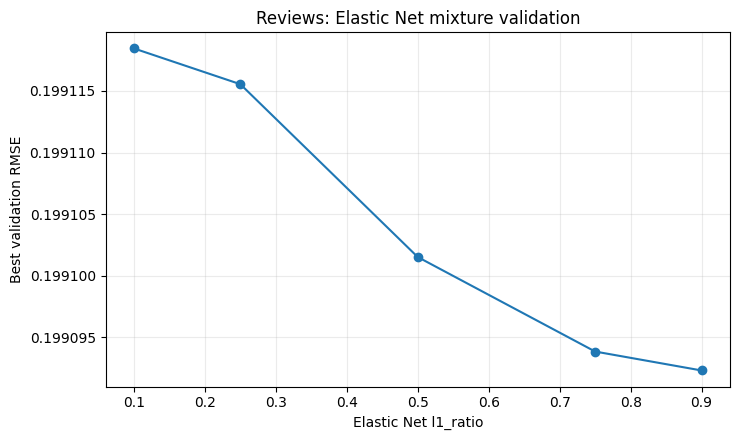

,Dataset,l1_ratio,best_validation_RMSE
0,Behavior,0.1000,15.9887
1,Behavior,0.2500,15.9887
2,Behavior,0.5000,15.9887
3,Behavior,0.7500,15.9887
4,Behavior,0.9000,15.9886
5,Churn,0.1000,17.6447
6,Churn,0.2500,17.6445
7,Churn,0.5000,17.6441
8,Churn,0.7500,17.6438
9,Churn,0.9000,17.6436


In [15]:
elastic_summary = (
    week2_results[
        week2_results["Model"] == "Elastic Net"
    ][
        [
            "Dataset",
            "alpha",
            "l1_ratio",
            "Nonzero coefficients",
            "RMSE",
            "R2",
        ]
    ]
    .reset_index(drop=True)
)

display(elastic_summary.round(4))

# All four datasets happened to select l1_ratio = 0.90.
# A bar chart of four identical 0.90 values would not add useful information.
# Instead, show WHY 0.90 was selected: for each l1_ratio, take the best
# validation RMSE obtained across the alpha grid.

elastic_ratio_summary = (
    elastic_curves
    .groupby(["Dataset", "l1_ratio"], as_index=False)
    .agg(
        best_validation_RMSE=("Validation RMSE", "min")
    )
)

for dataset_name in REG_TASKS:
    subset = elastic_ratio_summary[
        elastic_ratio_summary["Dataset"] == dataset_name
    ]

    fig, ax = plt.subplots(figsize=(7.5, 4.5))
    ax.plot(
        subset["l1_ratio"],
        subset["best_validation_RMSE"],
        marker="o",
    )
    ax.set_xlabel("Elastic Net l1_ratio")
    ax.set_ylabel("Best validation RMSE")
    ax.set_title(
        f"{dataset_name}: Elastic Net mixture validation"
    )
    ax.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

display(elastic_ratio_summary.round(5))

### Elastic Net observation

The validation curves explain the identical selected `l1_ratio` values better than a bar chart would.

All four searches selected `l1_ratio = 0.90`, so the best Elastic Net solutions lean toward Lasso. However, the curves are fairly shallow in several datasets. That means the exact mixture is not a strong business finding by itself.

For behavior, Elastic Net remains close to the other models but does not create the same sparsity as the selected Lasso model. For churn and products, the selected penalty is extremely small, which again suggests that ordinary regression is already competitive. Reviews show a small benefit from L1-style shrinkage, but the improvement is still modest.

## 10. Which terms did Behavior Lasso keep?

Behavior is the clearest Week 2 example because Lasso cuts the transformed feature set approximately in half while preserving test performance.

I inspect the surviving standardized coefficients to understand what the sparse model kept.

The coefficient sizes are easier to compare because the numeric inputs were standardized. I still do not interpret them causally.

In [16]:
behavior_lasso = fitted_models[("Behavior", "Lasso")]
behavior_features = prepared["Behavior"]["feature_names"]

behavior_lasso_terms = pd.DataFrame(
    {
        "Feature": behavior_features,
        "Coefficient": behavior_lasso.coef_,
    }
)

behavior_lasso_terms["Absolute coefficient"] = (
    behavior_lasso_terms["Coefficient"].abs()
)

surviving_behavior_terms = (
    behavior_lasso_terms[
        behavior_lasso_terms["Absolute coefficient"] > 1e-8
    ]
    .sort_values("Absolute coefficient", ascending=False)
)

display(surviving_behavior_terms.round(4))

,Feature,Coefficient,Absolute coefficient
0,num__Sales,45.4910,45.4910
1,num__Quantity,-8.5352,8.5352
2,num__Discount,-5.4967,5.4967
8,cat__Ship Mode_Second Class,4.7268,4.7268
6,cat__Segment_Home Office,0.1437,0.1437
15,cat__Order Priority_Medium,-0.0701,0.0701
4,num__Age,-0.0589,0.0589
3,num__Browsing Time (min),0.0315,0.0315


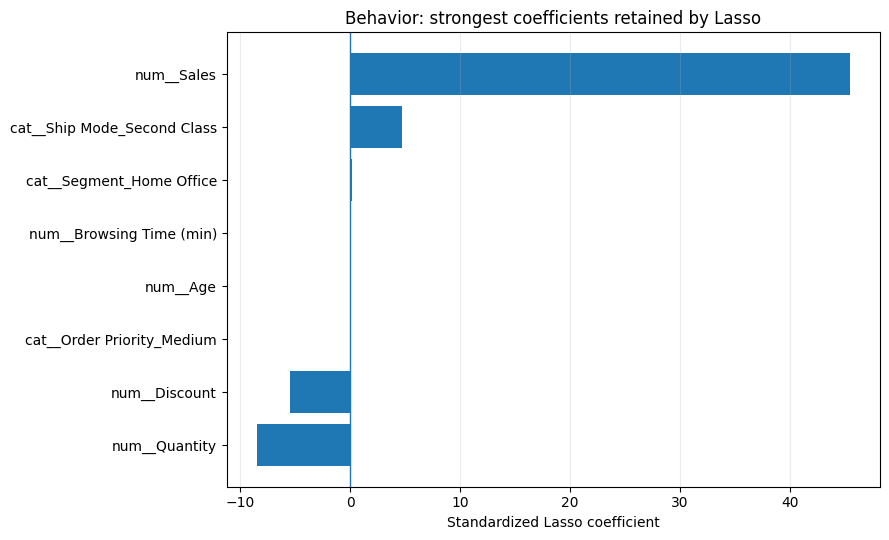

In [17]:
top_behavior_terms = (
    surviving_behavior_terms
    .head(12)
    .sort_values("Coefficient")
)

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(
    top_behavior_terms["Feature"],
    top_behavior_terms["Coefficient"],
)
ax.axvline(0, linewidth=1)
ax.set_xlabel("Standardized Lasso coefficient")
ax.set_title("Behavior: strongest coefficients retained by Lasso")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

### Behavior Lasso interpretation

The sparse behavior model keeps the core transaction signals and removes several low-contribution category indicators.

`Sales` remains the dominant positive signal, while quantity and discount retain substantial negative coefficients in this profit specification. A small number of shipping, segment, age, browsing, and priority terms also remain.

The important Week 2 result is not that Lasso discovered a completely different prediction function. It is that it produced nearly the same held-out performance with a materially smaller active feature set.

## 11. One holdout diagnostic for the model where regularization mattered most

The initial Week 2 notebook included a residual check. I keep that idea, but I do it only for the behavior Lasso model because that is where regularization creates the clearest simplification.

Repeating the same residual plot four times would add length without answering a new Week 2 question.

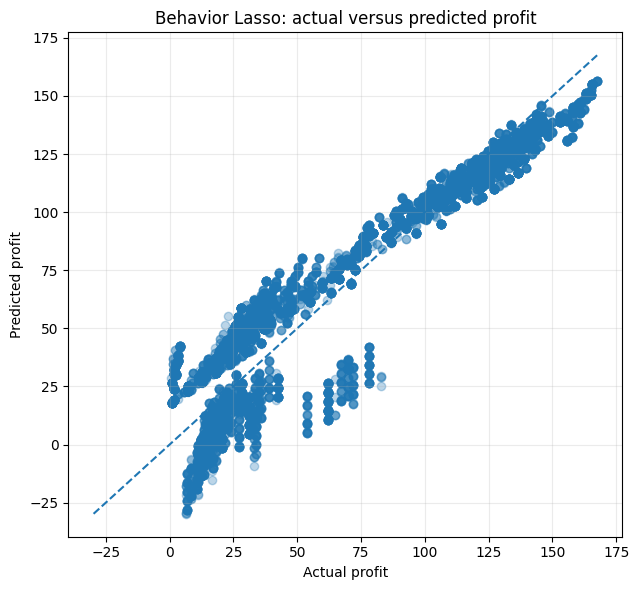

In [18]:
behavior_info = prepared["Behavior"]
behavior_lasso = fitted_models[("Behavior", "Lasso")]

behavior_prediction = behavior_lasso.predict(
    behavior_info["X_test"]
)
behavior_actual = behavior_info["y_test"]
behavior_residual = behavior_actual - behavior_prediction

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(
    behavior_actual,
    behavior_prediction,
    alpha=0.30,
)

lower = min(behavior_actual.min(), behavior_prediction.min())
upper = max(behavior_actual.max(), behavior_prediction.max())
ax.plot([lower, upper], [lower, upper], linestyle="--")

ax.set_xlabel("Actual profit")
ax.set_ylabel("Predicted profit")
ax.set_title("Behavior Lasso: actual versus predicted profit")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

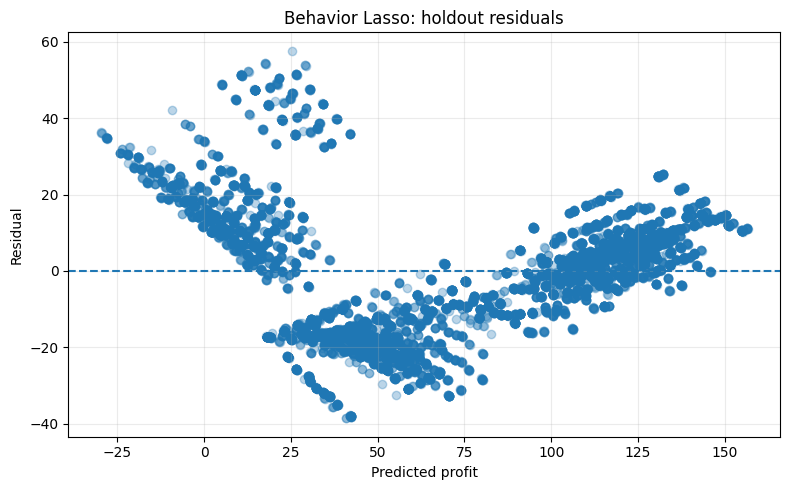

In [19]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(
    behavior_prediction,
    behavior_residual,
    alpha=0.30,
)
ax.axhline(0, linestyle="--", linewidth=1.5)
ax.set_xlabel("Predicted profit")
ax.set_ylabel("Residual")
ax.set_title("Behavior Lasso: holdout residuals")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 12. Dataset-by-dataset model decision

### Behavior

**Keep Lasso for the Week 2 comparison.** It reduces the active coefficient count from 16 to 8 while producing essentially the same test RMSE and R2 as OLS. The value here is parsimony, not a dramatic accuracy gain.

### Churn table

**Keep OLS as the practical choice for this continuous cashback task.** Ridge, Lasso, and Elastic Net all select penalties very close to zero and return almost identical results. This is a good example of when the unregularized model is reasonable.

### Products

**Do not force regularization.** Ridge is effectively identical to OLS, while the selected Lasso penalty slightly worsens held-out performance. The product sample is smaller, but sample size alone is not enough reason to prefer a penalty.

### Reviews

**Lasso is worth keeping as a small improvement, but only cautiously.** It slightly improves test RMSE and R2, although it does not remove any of the five structured predictors at the selected penalty. The main limitation is still the feature set: structured metadata cannot fully replace the information contained in review text.

## 13. What I found

The clearest Week 2 lesson is that **regularization changes model structure more consistently than it changes predictive accuracy**.

What stood out to me:

- Behavior Lasso is the strongest simplification result: roughly the same predictive performance with half as many active coefficients.
- The churn cashback model does not benefit from a meaningful penalty.
- The product model is another case where regularization is not automatically better.
- Review Lasso provides a small numerical improvement, but the structured model still leaves substantial variation unexplained.
- Elastic Net generally chose a Lasso-leaning mixture, but it did not create a clear advantage over simply using Lasso where sparsity mattered.
- Stronger alpha values eventually make every model worse because useful signal gets overshrunk.

This makes the Week 2 model-selection rule fairly practical:

- choose **Lasso** when simplification is useful and validation error stays competitive
- choose **Ridge** when correlated predictors should remain represented
- choose **Elastic Net** when a compromise is actually supported by validation evidence
- keep **OLS** when the penalty adds complexity to the workflow without improving generalization or interpretation

## 14. Overfitting controls and limitations

### How I controlled overfitting

- 20% of each dataset is kept as a final test set.
- A separate validation split is used to choose alpha and the Elastic Net mixture.
- Penalty strengths are searched on a logarithmic grid, as suggested in the Week 2 lesson.
- Scaling and categorical encoding are fit on training data only.
- Behavior splits are grouped by customer.
- Review splits are grouped by product.

### Limitations

- These are predictive associations, not causal estimates.
- The four outcomes have different units, so RMSE should be compared **within** a dataset rather than across datasets.
- A single validation split can be more variable than full cross-validation. The lecture notes identify cross-validation with grid or random search as another strong option for lambda selection.
- Lasso may choose one of several correlated predictors and suppress another, so a zero coefficient does not prove a variable has no business relevance.
- Ridge coefficients remain nonzero, so it does not provide the same direct feature-selection behavior as Lasso.
- Regularization cannot compensate for important variables that are missing from the dataset.

## 15. Source used for Week 2

### Course source

Boston University DX799 O1, Week 2 lesson: **Lasso, Ridge, and Elastic Net Regression**.

The lesson is the basis for the conceptual distinctions used in this notebook: Lasso can zero coefficients, Ridge generally retains them, Elastic Net combines both approaches, and the penalty strength should be searched over multiple values rather than selected arbitrarily.

### External source

scikit-learn developers, **Linear Models User Guide**  
https://scikit-learn.org/stable/modules/linear_model.html

I consider this a high-quality source because it is the primary documentation for the library used in the notebook and explains the implementation and parameterization of Lasso, Ridge, and Elastic Net.

### Reproducibility

- Random seed: 42
- Test set: 20%
- Validation set: 20% of the remaining training portion
- Penalty search: logarithmic alpha grid
- Elastic Net `l1_ratio` values: 0.10, 0.25, 0.50, 0.75, 0.90
- Numeric predictors are standardized before penalization
- Behavior splitting is customer-grouped
- Review splitting is product-grouped

In [20]:
# Save a compact machine-readable summary for later Milestone One synthesis.

Path("outputs").mkdir(exist_ok=True)

summary = {
    "week": 2,
    "topic": "Lasso, Ridge, and Elastic Net regression",
    "results": week2_results.to_dict(orient="records"),
}

Path("outputs/week2_summary.json").write_text(
    json.dumps(summary, indent=2)
)

print("Saved outputs/week2_summary.json")

Saved outputs/week2_summary.json
